# Principal Component Analysis: Wine Dataset

> **Authorship note.** This notebook was written by Claude (an AI assistant) on 22 November 2026 at the repository owner's request, as a reference implementation. It replaces a notebook that closely followed a public tutorial. It is not the owner's own work, and the owner has not yet reworked it.

Goal: reduce 13 chemical measurements of wines to a few principal components, see how much information each component keeps, and check how well a classifier works on the reduced data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold

## 1. Load the data

178 wines from three cultivars (classes 0, 1, 2), 13 features. The dataset ships with scikit-learn.

In [2]:
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name="cultivar")

print("Rows, columns:", X.shape)
print(y.value_counts().sort_index())
X.describe().loc[["mean", "std", "min", "max"]].round(2)

Rows, columns: (178, 13)
cultivar
0    59
1    71
2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91
min,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00


## 2. Standardise, then fit PCA

PCA looks for the directions of largest variance. Without scaling, `proline` (values in the hundreds) would dominate the first component simply because of its units, so every feature is first rescaled to mean 0 and standard deviation 1.

In [3]:
X_scaled = StandardScaler().fit_transform(X)
pca = PCA().fit(X_scaled)

explained = pd.DataFrame({
    "component": [f"PC{i}" for i in range(1, len(pca.explained_variance_ratio_) + 1)],
    "explained variance": pca.explained_variance_ratio_,
    "cumulative": np.cumsum(pca.explained_variance_ratio_),
})
explained.round(3)

,component,explained variance,cumulative
0,PC1,0.362,0.362
1,PC2,0.192,0.554
2,PC3,0.111,0.665
3,PC4,0.071,0.736
4,PC5,0.066,0.802
5,PC6,0.049,0.851
6,PC7,0.042,0.893
7,PC8,0.027,0.920
8,PC9,0.022,0.942
9,PC10,0.019,0.962


Components needed for 95% of the variance: 10 of 13


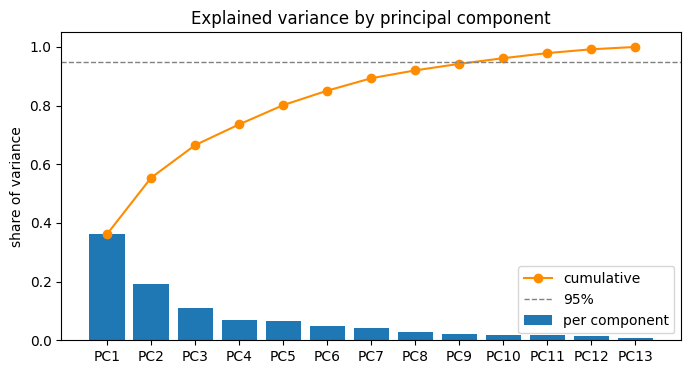

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(explained["component"], explained["explained variance"], label="per component")
ax.plot(explained["component"], explained["cumulative"], marker="o", color="darkorange", label="cumulative")
ax.axhline(0.95, color="grey", linestyle="--", linewidth=1, label="95%")
ax.set_ylabel("share of variance")
ax.set_title("Explained variance by principal component")
ax.legend()
plt.show()

n_95 = int(np.argmax(np.cumsum(pca.explained_variance_ratio_) >= 0.95) + 1)
print(f"Components needed for 95% of the variance: {n_95} of {X.shape[1]}")

## 3. Plot the wines on the first two components

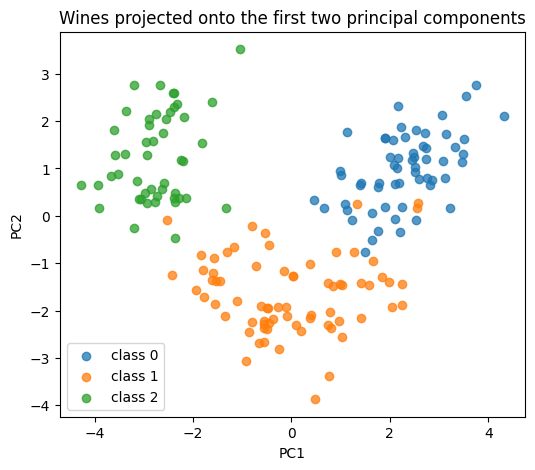

In [5]:
X_2d = PCA(n_components=2).fit_transform(X_scaled)

plt.figure(figsize=(6, 5))
for cls in sorted(y.unique()):
    mask = y == cls
    plt.scatter(X_2d[mask, 0], X_2d[mask, 1], label=f"class {cls}", alpha=0.75)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Wines projected onto the first two principal components")
plt.legend()
plt.show()

## 4. What the first two components are made of

The loadings show how much each original feature contributes to a component (sign = direction).

In [6]:
loadings = pd.DataFrame(pca.components_[:2].T, index=X.columns, columns=["PC1", "PC2"])
print("Largest contributions to PC1:")
print(loadings["PC1"].abs().sort_values(ascending=False).head(4).round(3), "\n")
print("Largest contributions to PC2:")
print(loadings["PC2"].abs().sort_values(ascending=False).head(4).round(3))

Largest contributions to PC1:
flavanoids                      0.423
total_phenols                   0.395
od280/od315_of_diluted_wines    0.376
proanthocyanins                 0.313
Name: PC1, dtype: float64 

Largest contributions to PC2:
color_intensity    0.530
alcohol            0.484
proline            0.365
ash                0.316
Name: PC2, dtype: float64


## 5. Does a classifier still work on fewer features?

Logistic regression is cross-validated on the full data and on PCA-reduced data. Scaling and PCA sit inside the pipeline, so they are re-fitted on each training fold and never see that fold's test data.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for n in [None, 2, n_95]:
    steps = [StandardScaler()] + ([PCA(n_components=n)] if n else []) + [LogisticRegression(max_iter=1000)]
    scores = cross_val_score(make_pipeline(*steps), X, y, cv=cv, scoring="accuracy")
    rows.append({"features used": "all 13" if n is None else f"{n} principal components",
                 "mean CV accuracy": scores.mean(), "std": scores.std()})
pd.DataFrame(rows).round(3)

,features used,mean CV accuracy,std
0,all 13,0.983,0.014
1,2 principal components,0.955,0.022
2,10 principal components,0.983,0.014


## Summary

- Standardise before PCA so that units do not decide the components.
- The explained-variance table shows how many components are worth keeping.
- Compare a model on the full and the reduced data with cross-validation, with PCA inside the pipeline.

All numbers above come from running this notebook.